# Histogram of Fluxes and Time Series

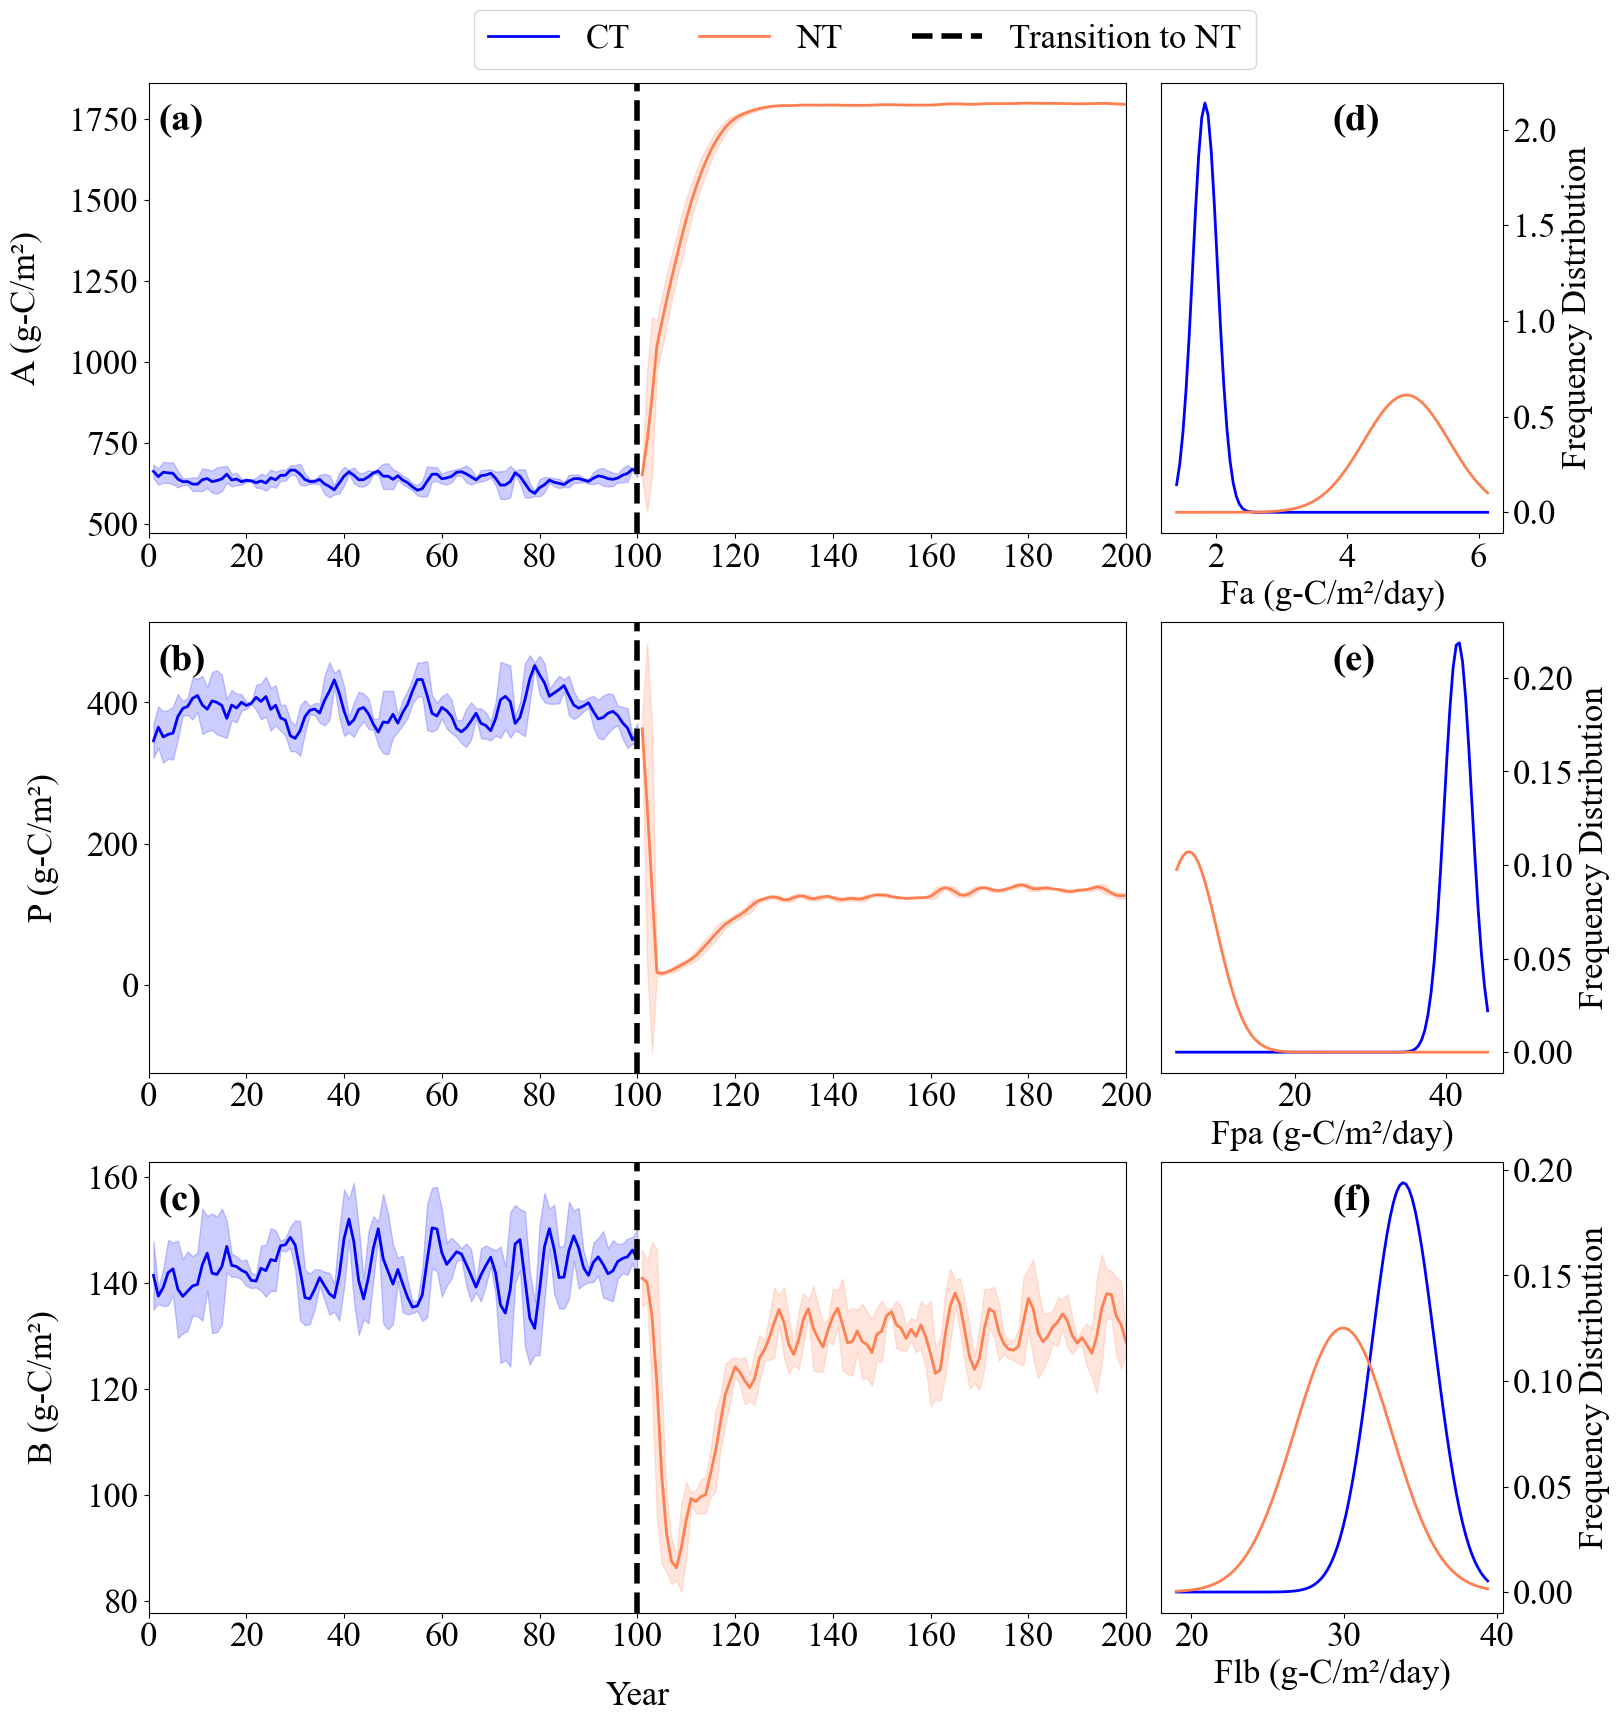

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib as mpl

# Set Times New Roman globally
mpl.rcParams['font.family'] = 'Times New Roman'

# Load data
data = pd.read_csv('AF.csv')

# Function to calculate rolling mean and confidence intervals
def calculate_rolling_stats(data, variable, window=3):
    rolling_mean = data[variable].rolling(window=window).mean()
    stderr = data[variable].rolling(window=window).std() / np.sqrt(window)
    ci = 1.96 * stderr
    lower_ci = rolling_mean - ci
    upper_ci = rolling_mean + ci
    return rolling_mean, lower_ci, upper_ci

# Function to plot variable with confidence intervals and PDF
def plot_variable_with_ci_and_normal_pdf(fig, ax_ts, ax_pdf, data, variable, flux_variable, window=3, labelsize=25):
    rolling_mean, lower_ci, upper_ci = calculate_rolling_stats(data, variable, window)

    tillage_mask = data['Years'].between(1401, 1500)
    no_tillage_mask = data['Years'].between(1501, 1600)
    x_range_tillage = np.arange(1, 101)
    x_range_notillage = np.arange(101, 201)

    # Time series plotting
    ax_ts.plot(x_range_tillage, rolling_mean[tillage_mask].values, color='blue', linewidth=2)
    ax_ts.plot(x_range_notillage, rolling_mean[no_tillage_mask].values, color='coral', linewidth=2)
    ax_ts.fill_between(x_range_tillage, lower_ci[tillage_mask].values, upper_ci[tillage_mask].values, color='blue', alpha=0.2)
    ax_ts.fill_between(x_range_notillage, lower_ci[no_tillage_mask].values, upper_ci[no_tillage_mask].values, color='coral', alpha=0.2)
    ax_ts.axvline(x=100, color='black', linestyle='--', linewidth=4)

    ax_ts.set_ylabel(f'{variable} (g-C/m\u00B2)', fontsize=labelsize, labelpad=20)
    ax_ts.set_xlim(1, 200)
    ax_ts.set_xticks(np.arange(0, 201, 20))
    ax_ts.tick_params(axis='both', which='major', labelsize=labelsize)

    # Convert yearly flux to daily flux
    flux_tillage = data[flux_variable][tillage_mask] * 24
    flux_notillage = data[flux_variable][no_tillage_mask] * 24

    mean_flux_t = flux_tillage.mean()
    std_flux_t = flux_tillage.std()
    mean_flux_nt = flux_notillage.mean()
    std_flux_nt = flux_notillage.std()

    x_range = np.linspace(min(flux_tillage.min(), flux_notillage.min()), 
                          max(flux_tillage.max(), flux_notillage.max()), 100)

    pdf_t = stats.norm.pdf(x_range, mean_flux_t, std_flux_t)
    pdf_nt = stats.norm.pdf(x_range, mean_flux_nt, std_flux_nt)

    # PDF plotting
    ax_pdf.plot(x_range, pdf_t, color='blue', linewidth=2)
    ax_pdf.plot(x_range, pdf_nt, color='coral', linewidth=2)
    ax_pdf.set_xlabel(f'{flux_variable} (g-C/m²/day)', fontsize=labelsize)
    if flux_variable == 'Flb':
        ax_pdf.set_ylabel('Frequency Distribution', fontsize=labelsize)
    else:
        ax_pdf.set_ylabel('Frequency Distribution', fontsize=labelsize)

    ax_pdf.yaxis.set_label_position("right")
    ax_pdf.yaxis.tick_right()
    ax_pdf.tick_params(axis='both', which='major', labelsize=labelsize)

# Main plotting section
fig = plt.figure(figsize=(30, 18))
variables = ['A', 'P', 'B']
flux_variables = ['Fa', 'Fpa', 'Flb']
panel_labels_ts = ['(a)', '(b)', '(c)']
panel_labels_pdf = ['(d)', '(e)', '(f)']
axes_ts = []
axes_pdf = []

for i, (var, flux_var) in enumerate(zip(variables, flux_variables)):
    ax_ts = fig.add_subplot(3, 2, i * 2 + 1)
    divider = make_axes_locatable(ax_ts)
    ax_pdf = divider.append_axes("right", size="35%", pad=0.35)

    if i == 2:
        plot_variable_with_ci_and_normal_pdf(fig, ax_ts, ax_pdf, data, var, flux_var)
    else:
        plot_variable_with_ci_and_normal_pdf(fig, ax_ts, ax_pdf, data, var, flux_var)
        ax_pdf.axis('on')

    axes_ts.append(ax_ts)
    axes_pdf.append(ax_pdf)

    if i == 0:
        
        ax_ts.text(0.01, 0.95, '(a)', transform=ax_ts.transAxes, fontsize=28, fontweight='bold', va='top', ha='left')
        ax_pdf.text(0.5, 0.95, '(d)', transform=ax_pdf.transAxes, fontsize=28, fontweight='bold', va='top', ha='left')
        
    elif i == 1:
        
        ax_ts.text(0.01, 0.95, '(b)', transform=ax_ts.transAxes, fontsize=28, fontweight='bold', va='top', ha='left')
        ax_pdf.text(0.5, 0.95, '(e)', transform=ax_pdf.transAxes, fontsize=28, fontweight='bold', va='top', ha='left')
        
    elif i == 2:
        ax_ts.text(0.01, 0.95, '(c)', transform=ax_ts.transAxes, fontsize=28, fontweight='bold', va='top', ha='left')
        ax_pdf.text(0.5, 0.95, '(f)', transform=ax_pdf.transAxes, fontsize=28, fontweight='bold', va='top', ha='left')

for ax in axes_ts[:-1]:
    ax.set_xlabel("")  

axes_ts[-1].set_xlabel('Year', fontsize=25, labelpad=20)

custom_lines = [
    plt.Line2D([0], [0], color='blue', linestyle='solid', lw=2, label='CT'),
    plt.Line2D([0], [0], color='coral', linestyle='solid', lw=2, label='NT'),
    plt.Line2D([0], [0], color='black', linestyle='--', lw=4, label='Transition to NT')
]
fig.legend(handles=custom_lines, loc='upper center', ncol=3, fontsize=25, bbox_to_anchor=(0.29, 0.98))

# Layout
plt.tight_layout()
plt.subplots_adjust(top=0.93, bottom=0.08)
fig.savefig("Model Working and Pools Getting Affected By Land Management Practice.pdf", format='pdf', bbox_inches='tight')
plt.show()